### Метод k-средних (K-means clustering)

K-Means — один из самых простых и эффективных алгоритмов кластеризации, который работает по принципу минимизации внутрикластерного расстояния. Цель состоит в том, чтобы сгруппировать похожие точки данных вместе и обнаружить базовые закономерности или структуры в данных.

K-means — это алгоритм на основе центроида или алгоритм на основе расстояния, где мы вычисляем расстояния для назначения точки кластеру. В K-means каждый кластер связан с центроидом.

Центроид — это средняя (центральная) точка кластера, которая минимизирует сумму расстояний до всех точек внутри этого кластера.

Если у нас есть кластер из nnn точек ​, то его центроид  вычисляется как среднее арифметическое всех точек:


Геометрически, центроид — это точка, вокруг которой сосредоточены все объекты кластера.

Оптимизация играет решающую роль в алгоритме кластеризации k-средних. Целью процесса оптимизации является поиск наилучшего набора центроидов, который минимизирует сумму квадратов расстояний между каждой точкой данных и ее ближайшим центроидом.

Как работает K-Means
Алгоритм K-Means пытается найти K кластеров в данных. Процесс работы состоит из нескольких шагов:

Выбирается число  — количество кластеров, на которые необходимо разбить данные.
Происходит инициализация центроидов.

Выбираются  случайных точек (центроидов), которые будут представлять центры будущих кластеров.

Назначаются точки кластерам.

Каждая точка данных присваивается ближайшему центроиду (например, по метрике Евклидова расстояния).

Происходит обновление центроидов.

Для каждого кластера вычисляется новый центроид — это среднее значение всех точек, принадлежащих кластеру.

Повторяются шаги 3–5 до сходимости алгоритма. Далее происходит проверка сходимости: если центроиды не изменились (или изменения малы), алгоритм завершает работу. В противном случае — возвращаемся к шагу 2.

![alt text](asset-v1_SkillFactory+MIFIML-2sem+2025+type@asset+block@MIFIML_CML_7M_01.jpg)

Отсюда же вытекают достоинства и недостатки K-Means.

Плюсы
Простота и скорость работы.
Хорошо работает на больших объемах данных.
Интерпретируемые результаты.
Минусы
Чувствителен к выбору начальных центроидов.
Требует заранее задавать число кластеров .
Плохо работает с кластерами сложной формы (не круглыми).
Отметим еще важный момент: как вычисляется расстояние между точками (между объектом и центроидом)? Кластеризация объектов происходит таким образом, чтобы минимизировать следующий критерий, сумму квадратов, расстояния между объектом и ближайшим к нему центроидом по всем кластерам, то есть значение.

Чаще всего используются следующие метрики расстояния:

Евклидово расстояние (обычное геометрическое расстояние).
Манхэттенское расстояние (L1-норма, «городские кварталы»).
Косинусное расстояние (косинусная мера различия).
Рассмотрим пример использования алгоритма K-Means на датасете сгенерированных точек, а затем обсудим оставшиеся нюансы.

Будем кластеризовать точки в двумерном пространстве с помощью библиотеки scikit-learn.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs

Сгенерируем простой набор данных их 300 точек (объектов), сгруппированных вокруг 3 центров (несмотря на то, что это обучение без учителя, для примера сгенерируем и правильные ответы).

C:\Users\troyd\AppData\Local\Temp\ipykernel_19908\1832006054.py:4: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(X[:, 0], X[:, 1], s=30, cmap='viridis')


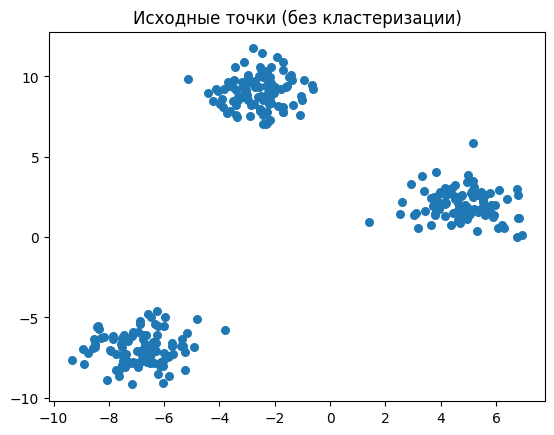

In [2]:
X, y = make_blobs(n_samples=300, centers=3, cluster_std=1.0, random_state=42)

# Визуализируем данные
plt.scatter(X[:, 0], X[:, 1], s=30, cmap='viridis')
plt.title("Исходные точки (без кластеризации)")
plt.show()

Теперь воспользуемся алгоритмом K-средних из библиотеки sklearn и будем разбивать данные на 3 кластера:

In [3]:
# Определяем K-Means с 3 кластерами
kmeans = KMeans(n_clusters=3, random_state=42)

# Обучаем модель
kmeans.fit(X)

# Получаем предсказанные метки кластеров
labels = kmeans.labels_

# Получаем координаты центроидов
centroids = kmeans.cluster_centers_

Так как это алгоритм машинного обучения без учителя, на этапе обучения fit() передаем ему только вектор признаков .
Визуализируем результат кластеризации с отображением центроидов:

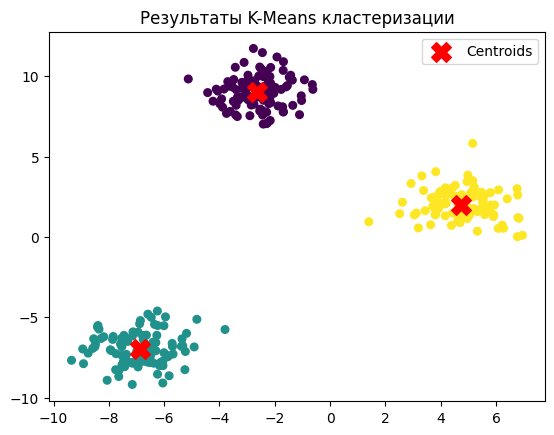

In [4]:
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis', s=30)
plt.scatter(centroids[:, 0], centroids[:, 1], c='red', marker='X', s=200, label='Centroids')
plt.title("Результаты K-Means кластеризации")
plt.legend()
plt.show()

### Настройка K-Means

K-Means требует заранее задать число кластеров , но как его выбрать? В предыдущем уроке при обучении K-Means вы самостоятельно выбрали количество кластеров — 3. Но оптимальное ли это число, и как найти оптимальное?

Если выбрать слишком маленькое значение, модель объединит несвязанные группы. Если выбрать слишком большое, алгоритм разобьет данные на слишком мелкие группы.

Есть несколько популярных методов для определения оптимального числа кластеров:

Метод локтя (Elbow Method).
Метод силуэта (Silhouette Score).
Рассмотрим каждый из них.

Метод локтя (Elbow Method)
Метод локтя основан на анализе суммы квадратов расстояний точек до ближайшего центроида (Within-Cluster Sum of Squares, WCSS).
Идея метода:

Вычисляем WCSS для разного количества кластеров (K).
Находим точку, где уменьшение WCSS резко замедляется (образуется «локоть»).
По сути, перебираем разное число кластеров и находим такое число кластеров, при котором перестает или почти перестает изменяться WCSS.

Возьмем для примера открытый датасет с Kaggle:

In [5]:
import os

# Замените на ваши данные из kaggle.json
os.environ['KAGGLE_USERNAME'] = "trpydenys"
os.environ['KAGGLE_KEY'] = "93fefce124761a787727499ed1e638d7"

In [7]:
# Пример для датасета Titanic
!kaggle datasets download -d rohan0301/unsupervised-learning-on-country-data

# Распаковка скачанного zip-архива
import zipfile
with zipfile.ZipFile('unsupervised-learning-on-country-data.zip', 'r') as zip_ref:
    zip_ref.extractall('df.k_means') # файлы появятся в папке 'data'

Dataset URL: https://www.kaggle.com/datasets/rohan0301/unsupervised-learning-on-country-data
License(s): MIT




  0%|          | 0.00/5.21k [00:00<?, ?B/s]
100%|██████████| 5.21k/5.21k [00:00<00:00, 1.99MB/s]


In [8]:
import pandas as pd

df = pd.read_csv(r"C:\IDE\2 семестр\Классическое МО\Модуль 7. Кластеризация\df.k_means\Country-data.csv")

Датасет содержит социально-экономические и медицинские показатели различных стран, влияющие на их общее развитие. Данные включают такие параметры, как ВВП на душу населения, ожидаемая продолжительность жизни, уровень грамотности, доступ к медицинской помощи и другие ключевые факторы. Цель анализа — кластеризовать страны на основе этих показателей, чтобы определить наиболее нуждающиеся регионы и помочь HELP International эффективно распределить 10 миллионов долларов гуманитарной помощи.

Давайте подберем оптимальное число кластеров для данного датасета. Для этого будем вычислять WCSS (Within-Cluster Sum of Squares) для разного числа кластеров:

Перебираем  от 1 до 14.
Для каждого  создаем модель KMeans(n_clusters=k).
Обучаем модель fit(X) и сохраняем метрику inertia_, которая показывает сумму квадратов расстояний точек до их центроидов (чем меньше, тем плотнее кластеры).

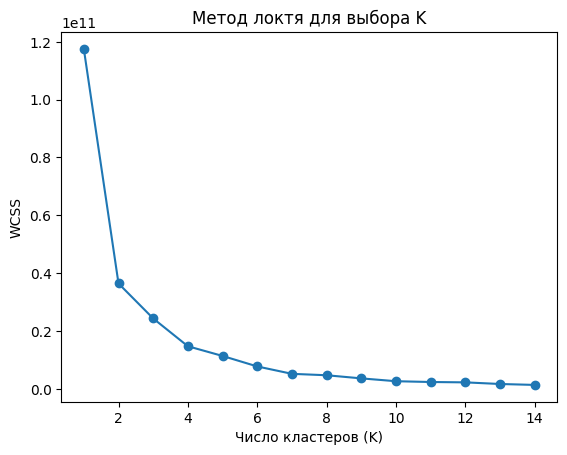

In [9]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Создадим вектор признаков
X = df.iloc[:, 1:]

# Считаем WCSS для разных K
wcss = []
K_values = range(1, 15)

for k in K_values:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)  # inertia_ -- сумма квадратов расстояний точек до центроидов

# Строим график
plt.plot(K_values, wcss, marker='o', linestyle='-')
plt.xlabel("Число кластеров (K)")
plt.ylabel("WCSS")
plt.title("Метод локтя для выбора K")
plt.show()

Оптимальное  — это точка, где WCSS перестает резко уменьшаться. На графике это выглядит как «изгиб» (локоть). В данном случае скорее всего подходит , потому что именно после 7 появляется асимптота, и изменения становятся крайне незначительными.

После подбора оптимального числа кластеров заново обучаем алгоритм KMeans на выбранном числе кластеров.

Но не всегда можно по графику локтя определить оптимальное число кластеров, так как в реальных данных не всегда есть явное разделение на кластеры. Даже в примере выше можно колебаться при выборе между 6, 7, 8 кластерами. Поэтому полезно использовать и другой метод выбора числа кластеров вместе с методом локтя — метод силуэта (Silhouette Score).

### Метод силуэта (Silhouette Score)
Метод силуэта позволяет оценить качество кластеризации и определить, насколько хорошо объекты внутри одного кластера схожи между собой и насколько они отделены от других кластеров.
Как рассчитывается коэффициент силуэта? Для каждого объекта  в кластере рассчитываются два значения:

Внутрикластерное расстояние  — среднее расстояние от точки  до всех других точек внутри ее кластера.
Межкластерное расстояние  — среднее расстояние от точки  до точек ближайшего соседнего кластера (того, к которому объект мог бы принадлежать, если бы не был в своем кластере).

Формула силуэтного коэффициента для объекта :

$s(i) = \frac{b(i) - a(i)}{max(a(i), b(i)}$

![alt text](asset-v1_SkillFactory+MIFIML-2sem+2025+type@asset+block@MIFIML_CML_7M_05.png)


Как интерпретировать полученное значение:

 1 → точка хорошо размещена внутри своего кластера, хорошо отделена от других.
 0 → точка расположена на границе между двумя кластерами.
 <0 → точка может быть неправильно определена к кластеру, так как она ближе к другому кластеру.
Общий силуэтный коэффициент (Silhouette Score) для всего кластера — это среднее значение  по всем объектам в кластере. А общий силуэт для всей модели — это среднее значение силуэта для всех кластеров.

Давайте рассмотрим пример расчета и визуализации силуэта для нашего датасета, чтобы точно определить какое число кластеров нам подходит — 6, 7 или 8:

In [10]:
from sklearn.metrics import silhouette_score

k_values = [6, 7, 8]
silhouette_scores = {}

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X)
    score = silhouette_score(X, labels)
    silhouette_scores[k] = score
    print(f"K = {k}, Silhouette Score: {score:.4f}")

K = 6, Silhouette Score: 0.5929
K = 7, Silhouette Score: 0.5950
K = 8, Silhouette Score: 0.5663


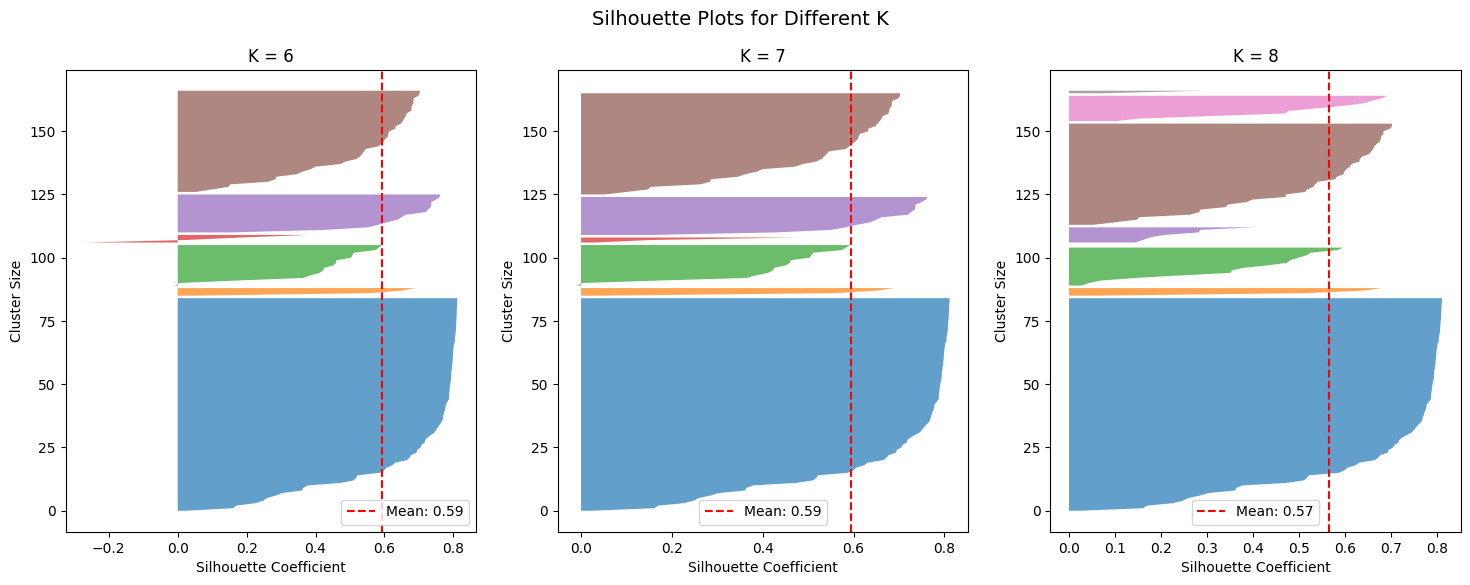

In [11]:
'''В целом результаты для 6 и 7 кластеров очень похожие и численные метрики не всегда отображаются полную картину, полезно посмотреть и на визуализацию силуэта:
'''
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_samples, silhouette_score
from sklearn.preprocessing import StandardScaler

# Функция для построения силуэтных графиков
def plot_silhouette(X, cluster_counts):
    fig, axes = plt.subplots(1, len(cluster_counts), figsize=(18, 6))

    for idx, K in enumerate(cluster_counts):
        kmeans = KMeans(n_clusters=K, random_state=42)
        cluster_labels = kmeans.fit_predict(X)

        # Вычисляем силуэтные коэффициенты
        silhouette_vals = silhouette_samples(X, cluster_labels)

        y_lower, y_upper = 0, 0
        axes[idx].set_title(f"K = {K}")
        
        for i in range(K):
            cluster_silhouette_vals = silhouette_vals[cluster_labels == i]
            cluster_silhouette_vals.sort()

            y_upper += len(cluster_silhouette_vals)
            axes[idx].fill_betweenx(
                np.arange(y_lower, y_upper), 
                0, 
                cluster_silhouette_vals, 
                alpha=0.7
            )
            y_lower = y_upper
        
        # Средний силуэтный коэффициент
        avg_score = silhouette_score(X, cluster_labels)
        axes[idx].axvline(avg_score, linestyle="--", color="red", label=f"Mean: {avg_score:.2f}")
        axes[idx].legend()
        axes[idx].set_xlabel("Silhouette Coefficient")
        axes[idx].set_ylabel("Cluster Size")
    
    plt.suptitle("Silhouette Plots for Different K", fontsize=14)
    plt.show()

# Вызываем функцию для K=6, 7, 8
plot_silhouette(X, cluster_counts=[6, 7, 8])

Как интерпретировать графики?

Один «нож» отвечает за один значение силуэта для одного кластера.
Ширина «ножа» (высота полосы).
Чем шире «нож» — тем больше объектов в этом кластере.
Если «нож» узкий, значит в этом кластере мало точек.
Разная высота «ножей» — кластеры несбалансированы.
Длина ножа (по оси X).
Чем длиннее нож — тем лучше кластеризация (высокий силуэт для данного кластера).
Длинные ножи (близко к 1) означают, что объекты хорошо разделены и далеки от соседних кластеров.
Короткие «ножи» (близко к 0) означают, что объекты плохо сгруппированы.
Острота ножа (форма распределения).
Острый (заостренный) нож — большинство объектов имеют похожий силуэтный коэффициент. Это хорошо.
Затупленный (размазанный) нож — сильный разброс значений силуэтного коэффициента. Это значит, что некоторые объекты слабо принадлежат кластеру.
Часть ножа уходит в отрицательную область.
Если часть ножа в отрицательной области — плохая кластеризация!
Отрицательные значения  означают, что точки находятся ближе к другому кластеру, чем к своему.
Это указывает на неправильно выбранное число кластеров  или наличие выбросов.
Также это может указывать на то, что кластеры наложились друг на друга.
 Таким образом, на самом деле для датасета оптимальное число кластеров — 7.
Рассмотрим для показательности другой график силуэта для другого набора данных и обсудим его интерпретацию, чтобы до конца закрепить и понять принцип его работы и интерпретации:

![alt text](asset-v1_SkillFactory+MIFIML-2sem+2025+type@asset+block@MIFIML_CML_7M_07.png)

Здесь график силуэтов представлен вместе с визуальной кластеризацией самих объектов. Из графика видно:

Синий нож самый широкий — в нем больше всего точек, что видно и на графике справа.
Также синий нож самый тупой, что свидетельствует и разбросе точек внутри кластера, что видно и на графике справа. Во всех остальных кластерах точки более скучены и содержат меньше выбросов.
У светло-зеленого ножа и серого часть силуэта уходят в отрицательную область. Это означает, что некоторые точки находятся на границе кластеров, либо кластеры наложились друг на друга.
Итог:

Нет универсального , все зависит от данных.
Всегда визуализируйте результаты.
Используйте несколько методов и сравнивайте результаты.

Некоторые недостатки вы уже знаете из предыдущих уроков:

Чувствителен к выбору начальных центроидов.
Требует заранее задавать число кластеров .
Плохо работает с кластерами сложной формы (не круглыми).
Давайте в этом уроке подробнее остановимся на третьем пункте.

Метод K-Means основан на минимизации расстояний до центроидов, что делает его особенно эффективным для сферических (круглых) кластеров.
Однако, когда данные имеют сложную форму (например, вытянутые, U-образные, или с несколькими плотностями), алгоритм начинает работать хуже.

K-Means делит пространство по прямым линиям:
K-Means использует евклидово расстояние, что приводит к линейным границам кластеров.
Если данные распределены не линейно (например, в форме полумесяца), K-Means не сможет их правильно разделить.
Пример
Например, два полукруга («луны»). Если у вас есть два полукруглых кластера, K-Means попытается разделить их по прямой, хотя логичнее было бы провести границу по изогнутой линии.
![alt text](asset-v1_SkillFactory+MIFIML-2sem+2025+type@asset+block@MIFIML_CML_7M_08.png)


Чувствительность к плотности точек.
Если один кластер размазан или имеет разную плотность, K-Means может создать несколько ложных кластеров вместо одного.
Это происходит, потому что алгоритм равномерно распределяет точки между центроидами, даже если один кластер на самом деле должен быть единым целым.
Рассмотрим один плотный кластер и один разреженный. Если один кластер компактный, а другой размазан, K-Means может разделить разреженный кластер на несколько частей.

Плохая работа с вложенными кластерами.
Если один кластер окружает другой (например, кольцо внутри круга), K-Means не сможет их корректно разделить, потому что центроиды будут стремиться к среднему положению.
Алгоритм не учитывает геометрию расположения точек и делит пространство по ближайшему среднему центру, а не по реальной структуре данных.
Хороший пример — «глаз быка» (кольцо вокруг центра). В такой ситуации K-Means не увидит кольцо и не разделит данные на внутренний и внешний круги, что не соответствует истинной структуре.

![alt text](asset-v1_SkillFactory+MIFIML-2sem+2025+type@asset+block@MIFIML_CML_7M_09.png)

Это одни из самых показательных примеров, что K-Means плохо работает со сложными формами кластеров и поэтому не всегда верно делит объекты на кластеры. В последующих уроках, мы посмотрим на более сложные алгоритмы, которые стараются нивелировать данный недостаток.